### 4.4 Definição do Hardware

In [2]:
# Verificar o status da GPU
!nvidia-smi

Thu Jul  9 19:35:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 4.5 Configuração do Ambiente (YOLOv8 e Dependências)

In [3]:
# Instala o motor Ultralytics (que roda YOLOv8 e YOLO11)
!pip install ultralytics
import ultralytics

# Verifica se o Colab te deu a placa de vídeo (GPU)
ultralytics.checks()

Ultralytics 8.4.90 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 46.7/112.6 GB disk)


### Conexão com a Nuvem (Google Drive)

In [4]:
from google.colab import drive
import os

# Montar o Google Drive
drive.mount('/content/drive')

# Desmontar o Google Drive
# drive.flush_and_unmount()

Mounted at /content/drive


### 4.3 Pré-processamento dos Datasets (Pipeline MLOps Automático)

In [5]:
import shutil
import yaml
import os

# 1. Caminhos
caminho_zip_drive = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Yolo_dataset.zip"
pasta_local_vm = "/content/Yolo_dataset"
yaml_path = f"{pasta_local_vm}/data.yaml"

# 2. Criar a pasta para não espalhar os arquivos
os.makedirs(pasta_local_vm, exist_ok=True)

# 3. Automação MLOps (Verifica se a pasta de imagens existe)
if not os.path.exists(f"{pasta_local_vm}/images"):
    print("🚚 1. Copiando o ZIP do Drive para o SSD da VM...")
    shutil.copy2(caminho_zip_drive, "/content/Yolo_dataset.zip")
    
    print("📦 2. Descompactando na velocidade da luz...")
    shutil.unpack_archive("/content/Yolo_dataset.zip", pasta_local_vm)
    print(" ✅ Descompactação concluída.")
else:
    print("✅ O dataset já está descompactado no SSD desta sessão!")

# 4. A Cirurgia do YAML (Só atua se o caminho estiver errado!)
if os.path.exists(yaml_path):
    with open(yaml_path, 'r') as f:
        data = yaml.safe_load(f)
    
    # Ele confere: O caminho atual já é o da VM local?
    if data.get('path') != pasta_local_vm:
        print("🔧 3. Ajustando o caminho no data.yaml existente...")
        data['path'] = pasta_local_vm
        with open(yaml_path, 'w') as f:
            yaml.dump(data, f, sort_keys=False)
        print(" 🚀 data.yaml atualizado com sucesso!")
else:
    print(" ⚠️ data.yaml não encontrado! O YOLO vai precisar dele para rodar.")

# 5. Aponta a variável global do YOLO para o SSD local
os.environ["DATASET_DIRECTORY"] = pasta_local_vm

🚚 1. Copiando o ZIP do Drive para o SSD da VM...
📦 2. Descompactando na velocidade da luz...
 ✅ Descompactação concluída.
🔧 3. Ajustando o caminho no data.yaml existente...
 🚀 data.yaml atualizado com sucesso!


### 4.6 Definição de Hiperparâmetros e 4.7 Treinamento do Modelo

In [6]:
import os
from datetime import datetime

DATASET_DIRECTORY = "/content/Yolo_dataset" 

# 1. Limpeza de Cache (Segurança)
!rm -f "$DATASET_DIRECTORY/labels/train/*.cache"
!rm -f "$DATASET_DIRECTORY/labels/val/*.cache"

# 2. Desativa W&B
os.environ["WANDB_DISABLED"] = "true"
print("W&B desativado.")

# 3. Configura a nova casa no Drive
agora = datetime.now()
nome_treino_v11 = agora.strftime("Treino_v11_%Y-%m-%d_%Hh%M")
# Criei uma pasta "Resultados_YOLOv11" para não misturar com o v5
diretorio_drive_v11 = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv11"

os.environ["NOME_TREINO_V11"] = nome_treino_v11
os.environ["DIRETORIO_DRIVE_V11"] = diretorio_drive_v11

print(f"🚀 Iniciando YOLOv11. Salvando direto no Drive em: {diretorio_drive_v11}/{nome_treino_v11}")

# 4. O comando mágico do YOLOv11
!yolo train model=yolo11s.pt data="$DATASET_DIRECTORY/data.yaml" epochs=2 batch=32 workers=4 project="$DIRETORIO_DRIVE_V11" name="$NOME_TREINO_V11" cache=disk

W&B desativado.
🚀 Iniciando YOLOv11. Salvando direto no Drive em: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv11/Treino_v11_2026-07-09_19h37
Ultralytics 8.4.90 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=disk, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, 

### 4.7 Inferência com o Conjunto de Testes

In [7]:
# Avalia o melhor peso do YOLO11 e cria a pasta Teste_Final
!yolo val model="$DIRETORIO_DRIVE_V11/$NOME_TREINO_V11/weights/best.pt" data="$DATASET_DIRECTORY/data.yaml" split=test project="$DIRETORIO_DRIVE_V11/$NOME_TREINO_V11" name="Teste_Final"

Ultralytics 8.4.90 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,414,735 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 58.1±25.7 MB/s, size: 158.4 KB)
val: Scanning /content/Yolo_dataset/labels/test... 1034 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1034/1034 406.0it/s 2.5s0.0s
val: /content/Yolo_dataset/images/test/000000099844.jpg: 2 duplicate labels removed
val: New cache created: /content/Yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 65/65 4.0it/s 16.2s0.2s
                   all       1034       7955      0.658      0.516      0.582      0.357
                person        839       4479      0.589      0.616      0.621      0.359
               bicycle        328        713      0.733       0.37      0.497      0.284
                   car        450       1660      0.651      0.502 

### 4.8 Coleta De metricas visuais

✅ Pasta de treino mais recente detectada automaticamente: Treino_v11_2026-07-09_19h37
📊 Lendo as métricas exatas da pasta: Treino_v11_2026-07-09_19h37
------------------------------------------------------------
>>> MÉTRICAS DE TREINAMENTO (Acurácia e Loss)


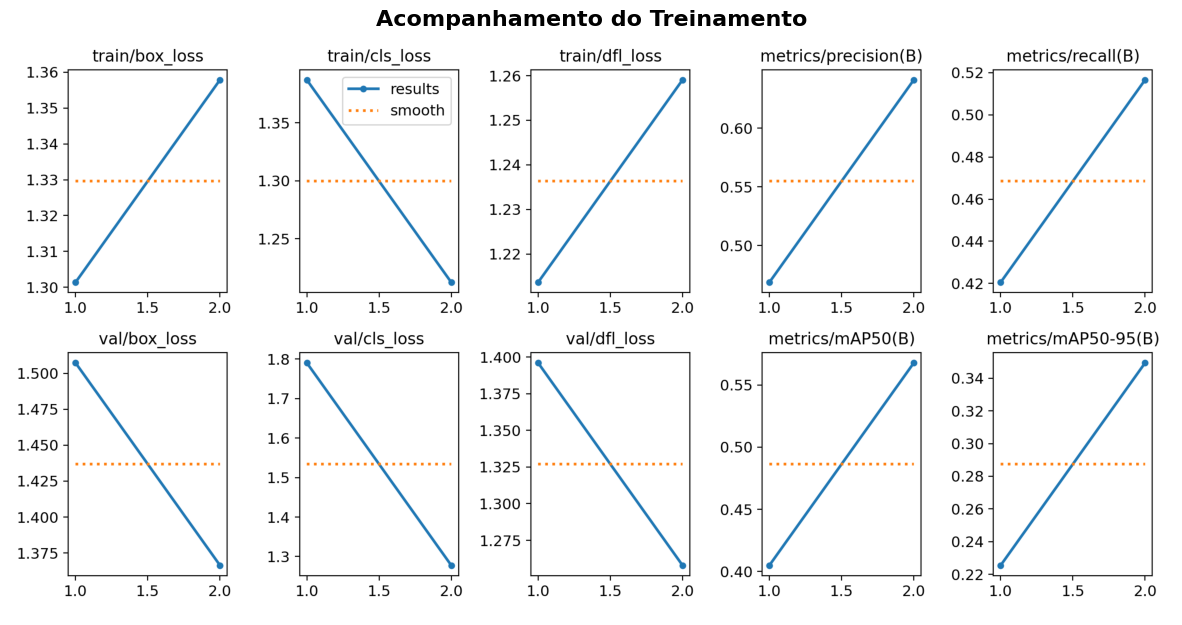


>>> MÉTRICAS DE TESTE (Avaliação Final)


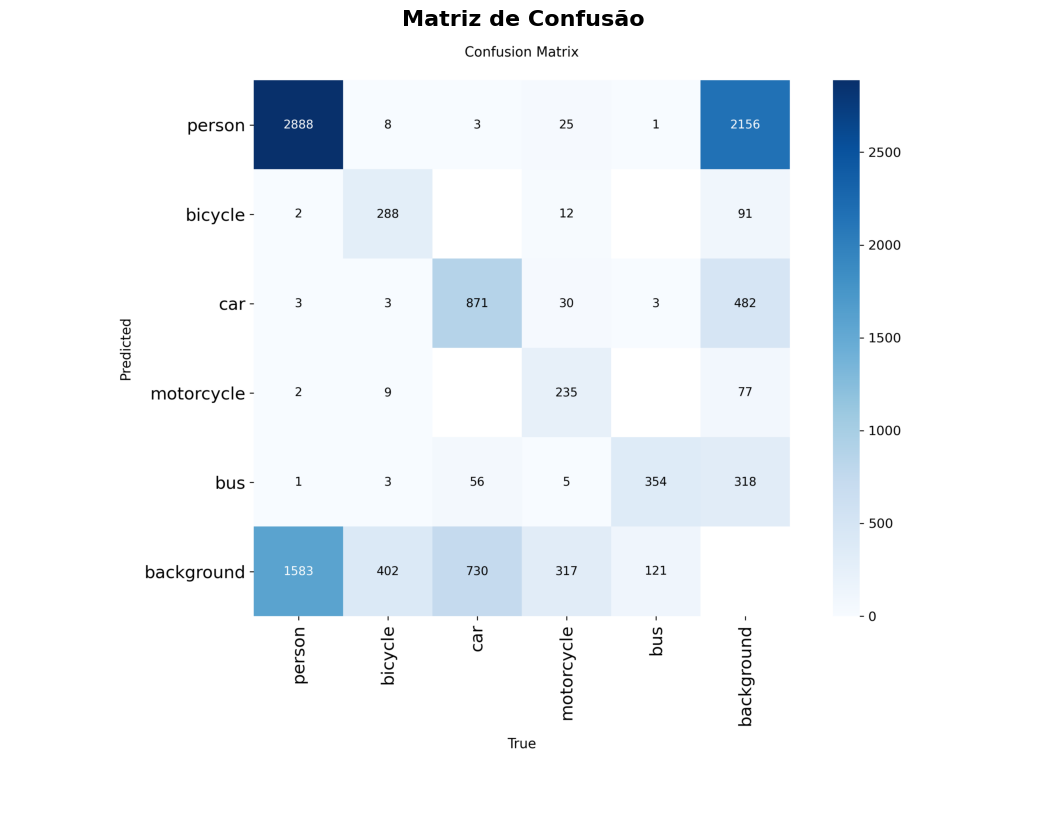

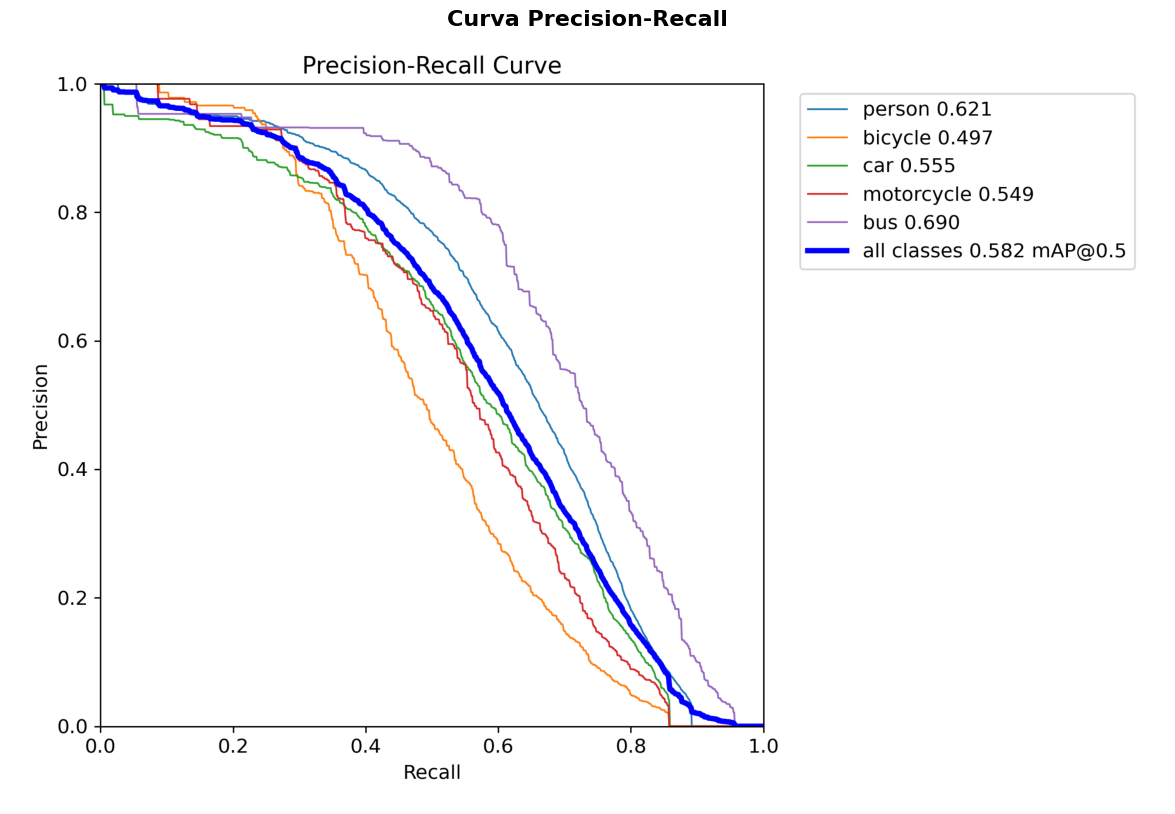


>>> INFERÊNCIA PRÁTICA (Ground Truth vs Predições)


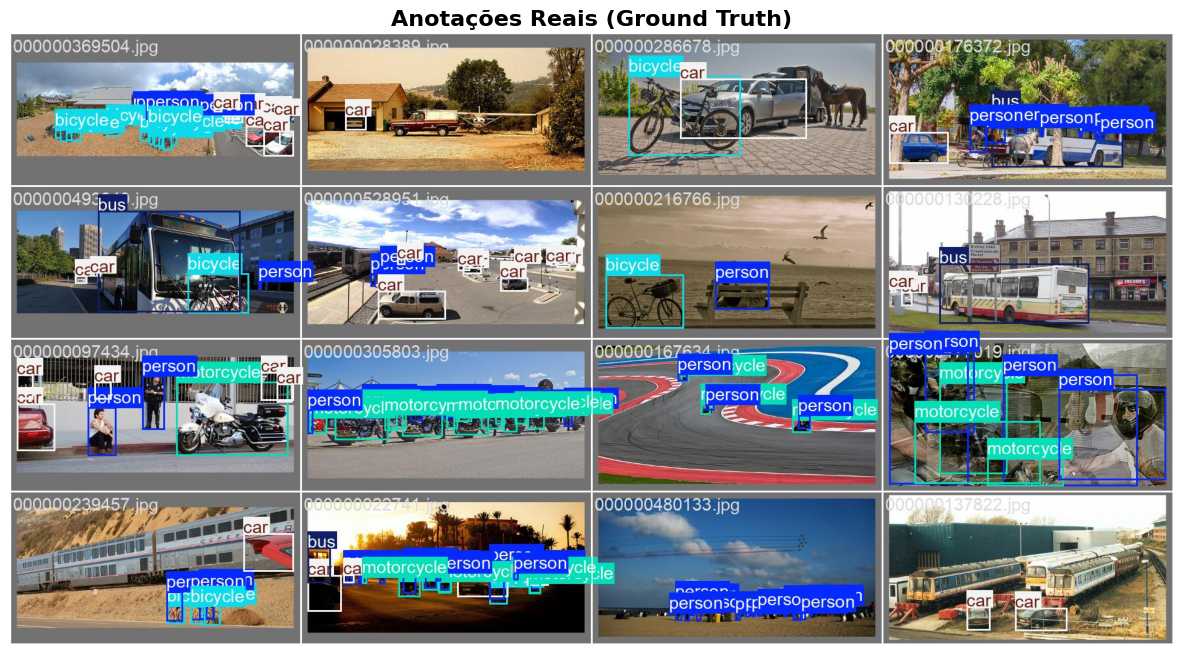

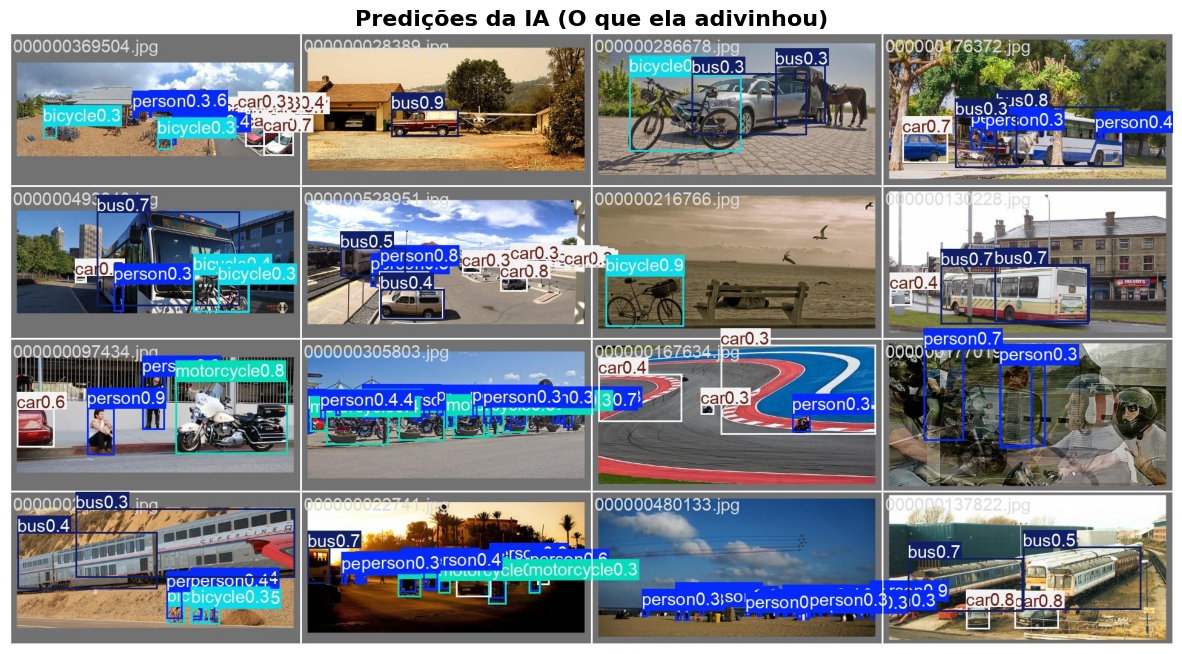


✅ Fluxo finalizado!


In [8]:
import matplotlib.pyplot as plt
import cv2
import os
import glob

def mostrar_metrica(caminho_imagem, titulo):
    img = cv2.imread(caminho_imagem)
    if img is not None:
        plt.figure(figsize=(15, 10))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(titulo, fontsize=16, fontweight='bold')
        plt.axis('off')
        plt.show()
    else:
        print(f"⚠️ Métrica não encontrada no Drive: {caminho_imagem}")

# 1. Diretório base onde todos os seus treinos do YOLOv11 estão salvos
diretorio_drive = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv11"

# 2. SELEÇÃO AUTOMÁTICA DA PASTA MAIS RECENTE
# Procura por todos os caminhos que começam com 'Treino_v11' dentro daquela pasta
pastas_treino = glob.glob(os.path.join(diretorio_drive, "Treino_v11*"))

if pastas_treino:
    # A mágica acontece aqui: max() encontra o caminho com o maior (mais recente) tempo de modificação (getmtime)
    pasta_mais_recente = max(pastas_treino, key=os.path.getmtime)
    # Extrai apenas o nome final da pasta (ex: "Treino_v11_2026-06-11_15h22")
    nome_treino_exato = os.path.basename(pasta_mais_recente)
    print(f"✅ Pasta de treino mais recente detectada automaticamente: {nome_treino_exato}")
else:
    print("⚠️ Nenhuma pasta de treino encontrada no Drive. Verifique se o treinamento foi concluído e os resultados foram salvos corretamente.")

# 3. Definição dos caminhos dinâmicos
pasta_treino_drive = f"{diretorio_drive}/{nome_treino_exato}"
pasta_teste_drive = f"{diretorio_drive}/{nome_treino_exato}/Teste_Final"

print(f"📊 Lendo as métricas exatas da pasta: {nome_treino_exato}")
print("-" * 60)

# 4. Gráficos do Treinamento
print(">>> MÉTRICAS DE TREINAMENTO (Acurácia e Loss)")
mostrar_metrica(f"{pasta_treino_drive}/results.png", "Acompanhamento do Treinamento")

print("\n>>> MÉTRICAS DE TESTE (Avaliação Final)")
mostrar_metrica(f"{pasta_teste_drive}/confusion_matrix.png", "Matriz de Confusão")
mostrar_metrica(f"{pasta_teste_drive}/BoxPR_curve.png", "Curva Precision-Recall")

print("\n>>> INFERÊNCIA PRÁTICA (Ground Truth vs Predições)")
mostrar_metrica(f"{pasta_teste_drive}/val_batch0_labels.jpg", "Anotações Reais (Ground Truth)")
mostrar_metrica(f"{pasta_teste_drive}/val_batch0_pred.jpg", "Predições da IA (O que ela adivinhou)")

print("\n✅ Fluxo finalizado!")